In [ ]:
import os

# Change to "cuda" before the first PyRITE import; restart an existing kernel.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()  # Fetch missing pinned tables once; reuse installed data.

# Predicting PXR line energies

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/03-pxr-line-energies.py)

Predict ideal HOPG resonance energies before simulating transport.
`photon_energies()` takes beam energy in **eV**, angles in **degrees**,
and returns a leading material axis even for one material. It is
analytic, so the controls below recompute instantly.

In [ ]:
from pyrite.materials import load_material_catalog
from pyrite.radiation import photon_energies

catalog = load_material_catalog()

In [ ]:
# Live in Molab or a local marimo session; the static page shows the defaults.
energy_keV = mo.ui.slider(10, 200, step=5, value=30, label="Electron energy (keV)")
tilt_deg = mo.ui.slider(0, 75, step=5, value=30, label="Sample tilt (°)")
observation_deg = mo.ui.slider(30, 160, step=5, value=135, label="Observation angle (°)")
reflection = mo.ui.dropdown(
    {"(002)": (0, 0, 2), "(004)": (0, 0, 4), "(006)": (0, 0, 6)},
    value="(002)",
    label="Reflection",
)
mo.vstack([energy_keV, tilt_deg, observation_deg, reflection])

<marimo-slider data-initial-value='135' data-label='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003eObservation angle (°)\u003c/span\u003e\u003c/span\u003e"' data-start='30' data-stop='160' data-step='5' data-steps='[]' data-debounce='false' data-disabled='false' data-orientation='"horizontal"' data-show-value='false' data-include-input='false' data-full-width='false'>

In [ ]:
from pyrite.units import ureg

angles_deg = np.linspace(30, 160, 131)
reference_keV = np.array([60.0, 100.0, 200.0])
# The analytic API takes numeric eV/degree magnitudes, not Pint objects.
beam_energies_eV = (np.r_[reference_keV, energy_keV.value] * ureg.keV).to("eV").magnitude
lines_eV = photon_energies(
    "hopg",
    beam_energies_eV[:, None],
    tilt_deg=tilt_deg.value,
    theta_obs_deg=angles_deg[None, :],
    hkl=reflection.value,
    catalog=catalog,
)[0]
selected_eV = float(
    photon_energies(
        "hopg",
        (energy_keV.value * ureg.keV).to("eV").magnitude,
        tilt_deg=tilt_deg.value,
        theta_obs_deg=observation_deg.value,
        hkl=reflection.value,
        catalog=catalog,
    )[0]
)

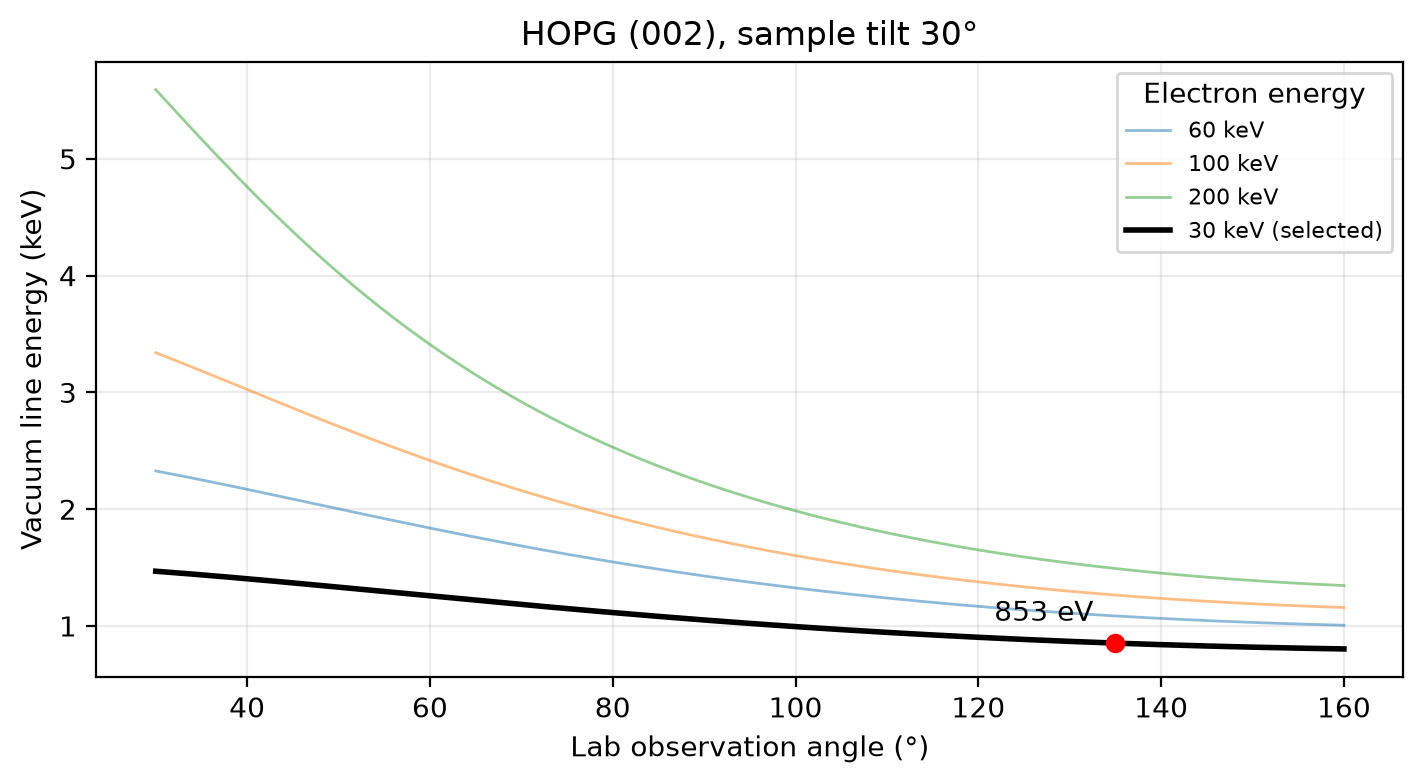

In [ ]:
figure, axis = plt.subplots(figsize=(7, 3.8), layout="constrained")
for _energy, _line in zip(reference_keV, lines_eV[:-1], strict=True):
    axis.plot(angles_deg, _line / 1_000, lw=1, alpha=0.5, label=f"{_energy:g} keV")
axis.plot(angles_deg, lines_eV[-1] / 1_000, "k", lw=2, label=f"{energy_keV.value:g} keV (selected)")
axis.plot(observation_deg.value, selected_eV / 1_000, "ro", zorder=3)
axis.annotate(
    f"{selected_eV:.0f} eV",
    (observation_deg.value, selected_eV / 1_000),
    textcoords="offset points",
    xytext=(-8, 8),
    ha="right",
)
axis.set(
    xlabel="Lab observation angle (°)",
    ylabel="Vacuum line energy (keV)",
    title=f"HOPG {reflection.selected_key}, sample tilt {tilt_deg.value:g}°",
)
axis.grid(alpha=0.25)
axis.legend(title="Electron energy", fontsize=8)
figure  # noqa: B018 - marimo renders the final expression

## Interpretation

These are **vacuum line centers**, not intensities or counts. Faster
electrons raise every line, most strongly near forward observation, because
the resonance energy scales as $\mathbf v\cdot\mathbf g/(1-\hat{\mathbf n}\cdot\mathbf v)$.
Tilting the sample rotates $\mathbf g$ relative to the beam and slides the
whole curve; higher orders of the same planes, such as (004), appear at
integer multiples of the (002) energy.

The model assumes straight electrons at their entrance energy and an ideal
lattice; it excludes transport, mosaic spread, in-medium dispersion and
response. A kinematically allowed line need not have measurable intensity.
Compare the selected point with notebook 01's spectrum, then see the
[physics and validation](https://pyrite.readthedocs.io/en/latest/physics/index.html)
documentation.

## Continue learning

Next: [Beams, crystals and target geometry](../designing/04-beams-crystals-target-geometry.ipynb).
See [photon-energy comparisons](../../reference/python-api/radiation.md#photon-energy-comparisons)
for API units and broadcasting, and [crystal tilt conventions](../../physics/geometry/tilt-convention.md)
for the orientation geometry. The [PXR amplitude evidence](../../validation/radiation-physics/pxr-amplitude.md)
describes the separate source model; line-centre prediction alone does not determine yield.

{download}`Download canonical Marimo notebook <../03-pxr-line-energies.py>`